# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [66]:
# Write your code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

# complete
print(f"Pandas version: {plt.matplotlib.__version__}")
print(f"Pandas version: {sns.__version__}")

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.4.6
Pandas version: 2.2.3
Pandas version: 3.10.0
Pandas version: 0.13.2


In [67]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [68]:
# Write your code here

S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
theta = ([0.3, 0.7])
bias = 0.5

# 1. Compute linear combination z
z = S @ theta + bias

# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5)
probabilities = 1 / (1 + np.exp(-z))

# Identify predicted spam emails
predicted_spam = probabilities >= bias

In [69]:
# Auto-graded cell (S)
# Skip it

In [70]:
# Auto-graded cell (theta)
# Skip it

In [71]:
# Auto-graded cell (bias)
# Skip it

In [72]:
# Auto-graded cell (z)
# Skip it

In [73]:
# Auto-graded cell (probabilities)
# Skip it

In [74]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [75]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [76]:
# Auto graded cell (log)
# skip it

In [77]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"

# Write your code here
log.loc[rng.choice(n, 12, replace=False), "failed_attempts"] = rng.integers(5, 11, 12)

In [78]:
# Autograded cell (Failed attempts)
# Skip it

In [79]:
# Insert 10 missing values randomly

# Write your code here
log.loc[rng.choice(n, 10, replace=False), "duration_min"] = np.nan

In [80]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [81]:
# Write your code here

ru_log_at_least_five_attempts = len(log[(log["country"] == "RU") & (log["failed_attempts"] >= 5)])
print(ru_log_at_least_five_attempts)

2


In [82]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [83]:
# Write your code here

user_max_failed_attempts = log.groupby("user")["failed_attempts"].sum().sort_values(ascending=False).index[0]
print(user_max_failed_attempts)

yacine


In [84]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [85]:
# Write your code here
log['long_session'] = (log['duration_min'] > 30).astype(int)

In [86]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

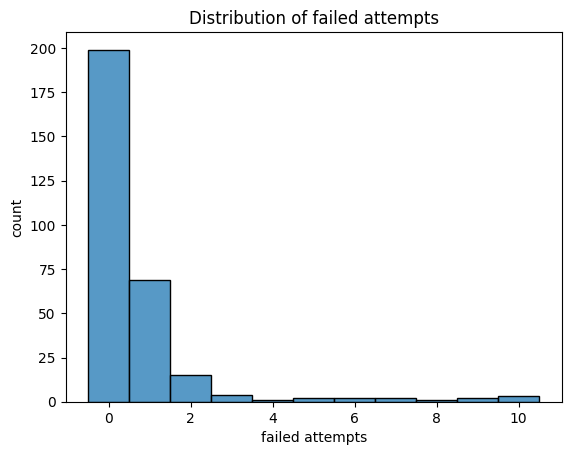

In [87]:
# Draw the histogram of failed_attempts.
# Write your code here
sns.histplot(log["failed_attempts"], bins=range(0, 12), discrete=True)
plt.title("Distribution of failed attempts")
plt.xlabel("failed attempts")
plt.ylabel("count")
plt.show()

In [88]:
# Auto-graded cell - Skip it...

In [89]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

IndentationError: unexpected indent (1357432129.py, line 2)

In [90]:
# Write your code here
answer_q2 = "B"

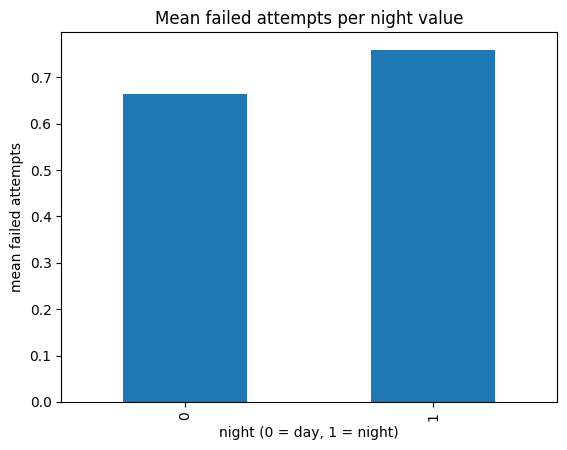

In [91]:
# 3. Draw a bar chart of the mean failed_attempts per night value.

# Write your code here
log["night"] = (log["hour"] < 6).astype(int)      # 1 if the login is at night
log.groupby("night")["failed_attempts"].mean().plot.bar(title="Mean failed attempts per night value")
plt.xlabel("night (0 = day, 1 = night)")
plt.ylabel("mean failed attempts")
plt.show()

In [92]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [93]:
# Write your code here
# Please write a sentence response instead of code
# X[:, 2] returns the third column (index 2) of X, the values of the 3rd feature for all 300 samples.

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [94]:
# Write your code here
log.isna().sum()
# Or using the actual notebook DataFrame:
# log.isna().sum()

,0
user,0
hour,0
failed_attempts,0
country,0
duration_min,10
long_session,0
night,0


Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

<Axes: xlabel='country', ylabel='failed_attempts'>

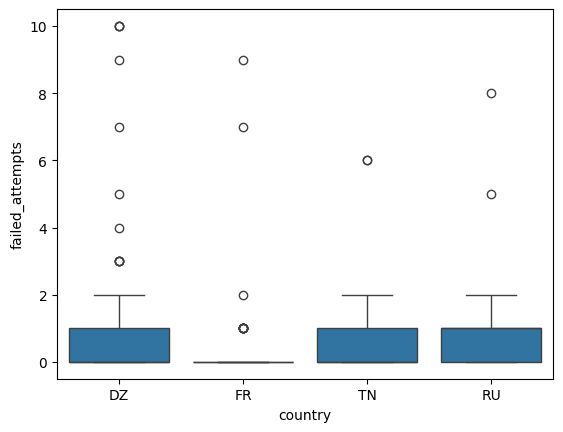

In [95]:
# Write your code here
sns.boxplot(data=log, x="country", y="failed_attempts")

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [96]:
# Write your code here
# Scaling puts all features on the same scale (mean 0, std 1) so that features with large values (e.g. area) do not dominate the others and gradient descent converges faster.

Commit the logins_clean.csv.(0.5 point)

In [98]:
# save the cleaned table in login_clean.csv
# Write your code here
log["duration_min"] = log["duration_min"].fillna(log["duration_min"].median())
log["night"] = (log["hour"] < 6).astype(int)
log.to_csv("logins_clean.csv", index=False)

In [97]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [99]:
# Write your code here

In [100]:
import numpy as np
import pandas as pd
